# Start years needed for the lead-time climatology

How many start years are needed for the lead-time (drift) climatology? For each experiment the drift climatology and the paired observed climatology are built from K random start years and removed from every year; all years are then scored without detrending.

* Subtracting a lead-time climatology shifts each lead and grid point by a constant, which leaves ACC (and any detrended score) unchanged, so the climatology sample size shows up only in the non-detrended RMSE and in the climatology estimate itself.
* **In-sample** removes one climatology built from K random years from all years (the workflow uses all years; reference K = N). **Cross-validated** gives each scored year its own climatology from K years drawn among the *other* years, as a real forecast would face (reference K = N − 1, leave-one-out).
* Absolute RMSE is used: with a cross-validated climatology the sampling noise inflates the forecast and observed anomalies alike, so it cancels in nRMSE.
* Dashed grey: the sampling-only expectation for independent, trend-free errors, √((1 + 1/K − 2/N)/(1 − 1/N)) in-sample and √((1 + 1/K)/(1 + 1/(N − 1))) cross-validated; e.g. a 5 % RMSE tolerance needs K ≈ 10 (√(1 + 1/K) ≤ 1.05). Departures come from trends and autocorrelation in the errors.

**Definitions** (identical to `stats.compute_skill_seasonal`, verified in `tests/test_sample_size_skill.py`):
ACC is the Pearson correlation of the ensemble-mean and observed anomalies over the selected years;
nRMSE is their RMSE divided by the observed standard deviation; with `DETREND = True` a linear trend
in initialization year is removed from both first. Area means average the score maps (cos-latitude
weights) over each region. Inputs are only read (test root first, then production): run 1a_atm (TS,
TREFHT, PRECT, PSL), 3a and 1a_lnd first for any field you want here. Shared loading, region means and
plotting live in `workflows/diagnostics/sample_size.py`.

Experiments: E3SMv3-FOSIRL and E3SMv3-Reanalysis, the two hindcasts with complete long records (May
starts 1980–2018), so the results rest on the full record.

In [1]:
# Test-run output roots (set before importing esp_lab so every module sees them).
import os
os.environ["ESP_LAB_FIGURE_ROOT"] = "/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test"
os.environ["ESP_LAB_S2D_DIAG_ROOT"] = "/global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test"
os.environ["ESP_LAB_FIGURE_GALLERY"] = "0"  # test runs: figures only, no figures.json/index.html

%matplotlib inline
from pathlib import Path

import numpy as np
import pandas as pd

from esp_lab import env_paths
from esp_lab import sample_size_skill as sss
from workflows.diagnostics import sample_size as ss

In [2]:
# =============================================================================
# CONFIGURATION BLOCK: Edit settings here
# =============================================================================
INIT_MONTH = 5
RANDOM_SEED = 42
N_DRAWS = 100               # random subsets per sample size
RUN_GROUPS = ["atm", "sst", "lnd"]   # drop groups to shorten a run
QUICK = False               # True: 40 draws and the first field of each group only

# The two experiments with complete long hindcast records (May starts 1980-2018), so every
# curve rests on the full record. "years" is the start-year span a cache must lie within.
EXPERIMENTS = {
    "E3SM-FOSIRL":     dict(tag="JRA55_FOSIRL", label="E3SMv3-FOSIRL",     color="black",    years=(1980, 2018)),
    "E3SM-Reanalysis": dict(tag="Reanalysis",   label="E3SMv3-Reanalysis", color="tab:blue", years=(1980, 2018)),
}
MIN_YEARS = 6               # experiments with fewer observed start years are skipped for that field

ATM_FIELDS = ["TS", "TREFHT", "PRECT", "PSL"]
SST_INDICES = ["Nino3.4", "Nino3", "Nino4", "IOD", "TNA", "AtlNino"]
LAND_FIELDS = ["H2OSNO", "H2OSOI", "TWS"]

# Regions for gridded fields: (lat0, lat1, surface); land fields use finite land points.
ATM_REGIONS = {
    "Global 60S-80N": (-60, 80, "all"), "Land 60S-80N": (-60, 80, "land"),
    "Ocean 60S-60N": (-60, 60, "ocean"), "Tropics 20S-20N": (-20, 20, "all"),
}
LAND_REGIONS = {"Land 60S-80N": (-60, 80, "all"), "NH 30N-80N": (30, 80, "all")}

# Figures: one row per field/index, one column per lead (positions in each group's lead axis).
PLOT_REGION = {"atm": "Global 60S-80N", "lnd": "Land 60S-80N", "sst": "index"}
PLOT_LEADS = {"atm": [0, 2, 4], "sst": [0, 2, 4], "lnd": [0, 1, 2]}
MEMBERS = 10                # members used for every experiment (a fixed random subset if more)
K_GRID = [1, 2, 3, 4, 5, 6, 8, 10, 12, 14, 16, 20, 24, 28, 32]   # climatology years (above a record: dropped)
CLIM_TOLERANCE = 0.05       # "stable": median RMSE <= (1+tol)x and 95th pct <= (1+2 tol)x the large-K value
# ===== END CONFIGURATION BLOCK =====

## Inputs

For every experiment and field the longest cached record inside its span is used; only start years with observations are kept. The table lists what was found.

In [3]:
if QUICK:
    N_DRAWS = 40
    ATM_FIELDS, SST_INDICES, LAND_FIELDS = ATM_FIELDS[:1], SST_INDICES[:1], LAND_FIELDS[:1]

S2D_DIAG_ROOT = env_paths.s2d_diag_root()
READ_ROOTS = list(dict.fromkeys([S2D_DIAG_ROOT, Path("/global/cfs/cdirs/e3sm/S2S2D/s2d_diag")]))
FIGURE_DIR = env_paths.figure_root() / "sample_size"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR = S2D_DIAG_ROOT / "multimodel" / "sample_size"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(RANDOM_SEED)

GROUP_FIELDS = {"atm": ATM_FIELDS, "sst": SST_INDICES, "lnd": LAND_FIELDS}
DATA, inventory = ss.load_inputs(
    {group: GROUP_FIELDS[group] for group in RUN_GROUPS}, EXPERIMENTS,
    read_roots=READ_ROOTS, init_month=INIT_MONTH, min_years=MIN_YEARS,
)
REDUCE = ss.region_reducers(READ_ROOTS, ATM_REGIONS, LAND_REGIONS)
PLOT = dict(experiments=EXPERIMENTS, plot_region=PLOT_REGION, plot_leads=PLOT_LEADS)
print(f"Read roots: {[str(r) for r in READ_ROOTS]}\nFigures: {FIGURE_DIR}\nTables: {TABLE_DIR}")
inventory.drop(columns="file", errors="ignore").fillna("")

Read roots: ['/global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test', '/global/cfs/cdirs/e3sm/S2S2D/s2d_diag']
Figures: /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size
Tables: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/multimodel/sample_size


,group,field,experiment,status,years,n_years,members
0,atm,TS,E3SM-FOSIRL,used,1980-2017,38,10
1,atm,TS,E3SM-Reanalysis,used,1980-2017,38,10
2,atm,TREFHT,E3SM-FOSIRL,used,1980-2017,38,10
3,atm,TREFHT,E3SM-Reanalysis,used,1980-2017,38,10
4,atm,PRECT,E3SM-FOSIRL,used,1980-2015,36,10
5,atm,PRECT,E3SM-Reanalysis,used,1980-2015,36,10
6,atm,PSL,E3SM-FOSIRL,used,1980-2011,32,10
7,atm,PSL,E3SM-Reanalysis,used,1980-2011,32,10
8,sst,Nino3.4,E3SM-FOSIRL,used,1980-2018,39,10
9,sst,Nino3.4,E3SM-Reanalysis,used,1980-2018,39,10


## RMSE vs. start years in the climatology

/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


/global/u2/z/zhan391/code/ESP-Lab/esp_lab/sample_size_skill.py:244: RuntimeWarning: Mean of empty slice
  clim_error = np.sqrt(np.nanmean(error ** 2, axis=1))


/global/u2/z/zhan391/code/ESP-Lab/esp_lab/sample_size_skill.py:244: RuntimeWarning: Mean of empty slice
  clim_error = np.sqrt(np.nanmean(error ** 2, axis=1))


/global/u2/z/zhan391/code/ESP-Lab/esp_lab/sample_size_skill.py:244: RuntimeWarning: Mean of empty slice
  clim_error = np.sqrt(np.nanmean(error ** 2, axis=1))


/global/u2/z/zhan391/code/ESP-Lab/esp_lab/sample_size_skill.py:244: RuntimeWarning: Mean of empty slice
  clim_error = np.sqrt(np.nanmean(error ** 2, axis=1))


/global/u2/z/zhan391/code/ESP-Lab/esp_lab/sample_size_skill.py:244: RuntimeWarning: Mean of empty slice
  clim_error = np.sqrt(np.nanmean(error ** 2, axis=1))


... (3,246 outputs left out)

/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/global/u2/z/zhan391/code/ESP-Lab/esp_lab/sample_size_skill.py:244: RuntimeWarning: Mean of empty slice
  clim_error = np.sqrt(np.nanmean(error ** 2, axis=1))


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


done: lnd H2OSOI
done: lnd TWS


Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_climatology_rmse_in-sample_atm.png


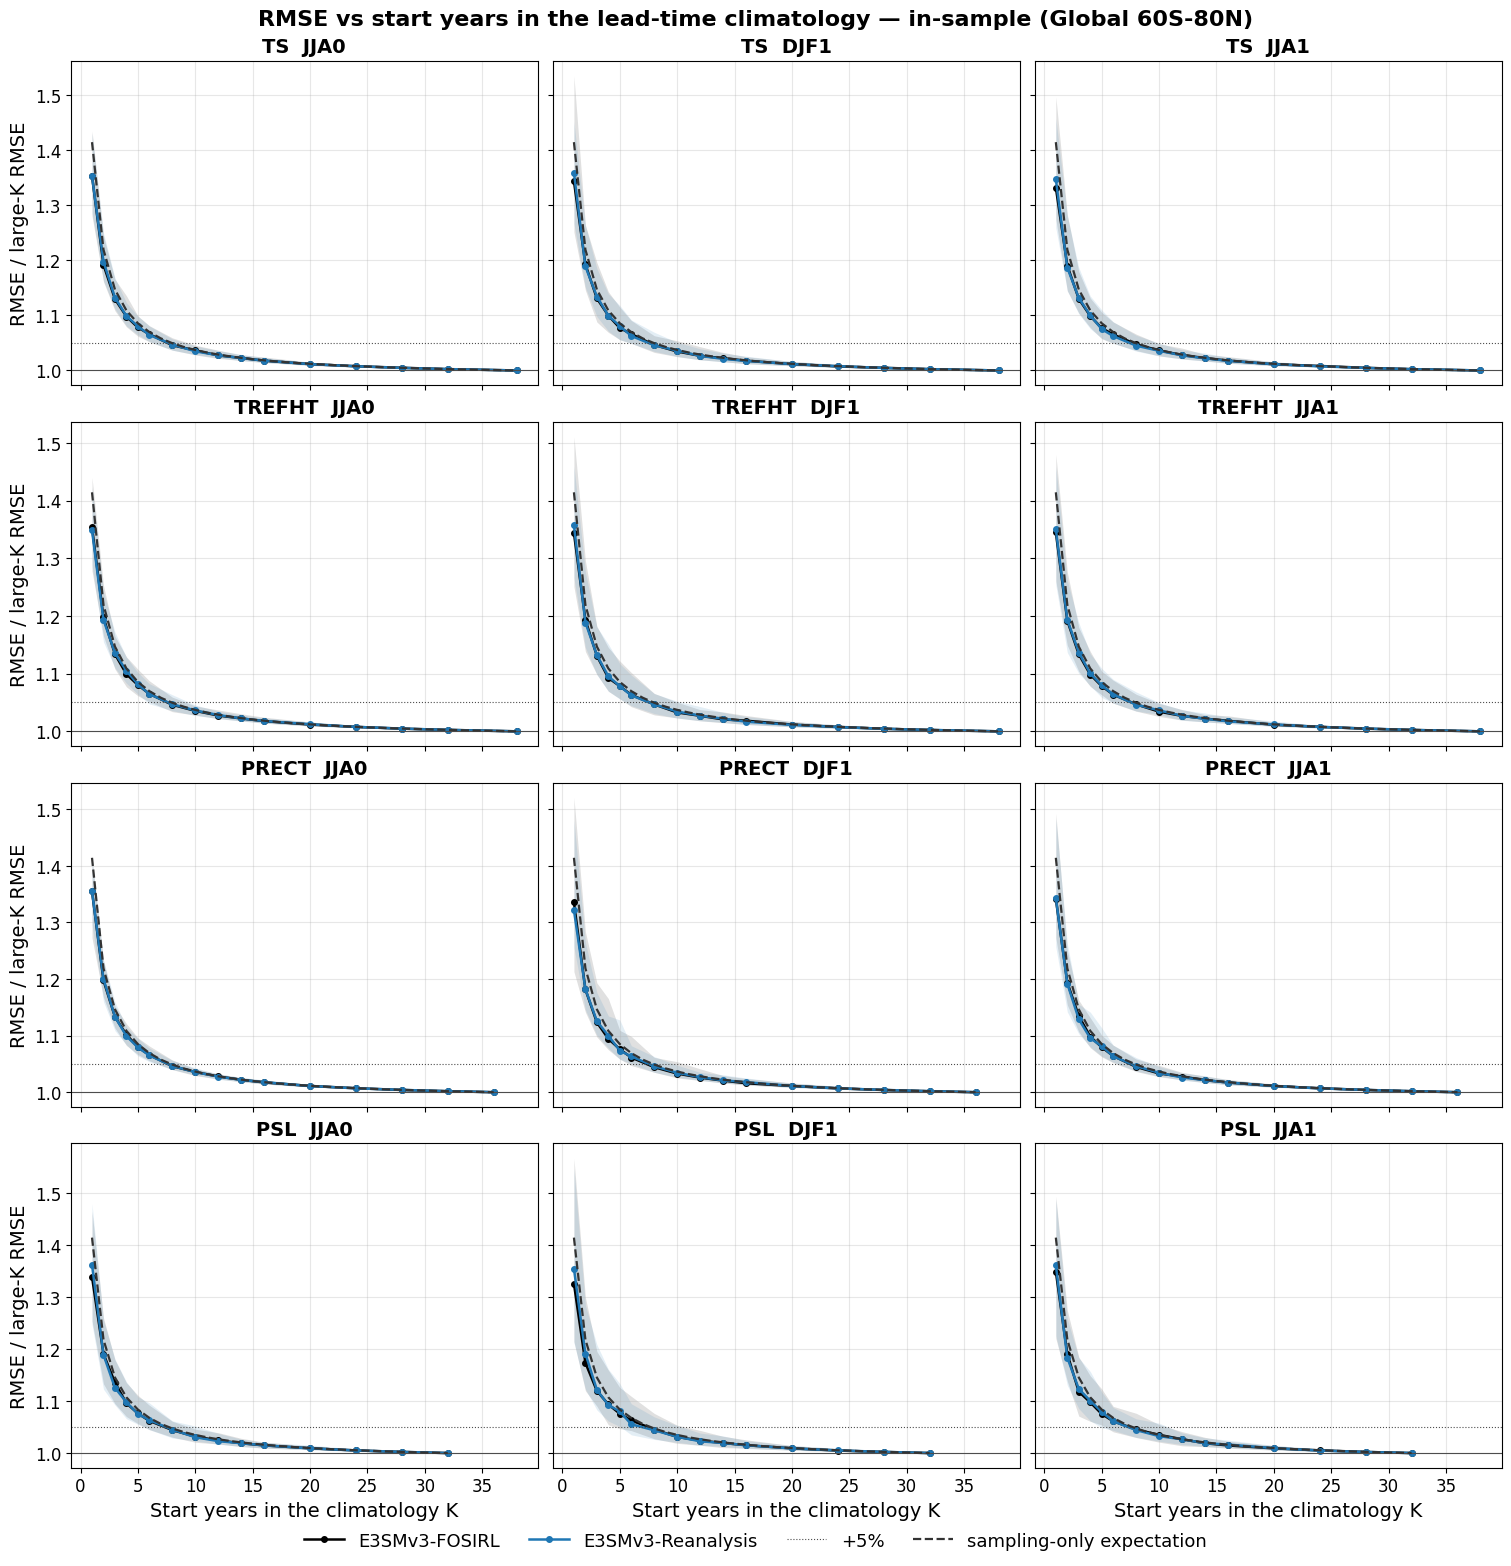

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_climatology_rmse_cross-validated_atm.png


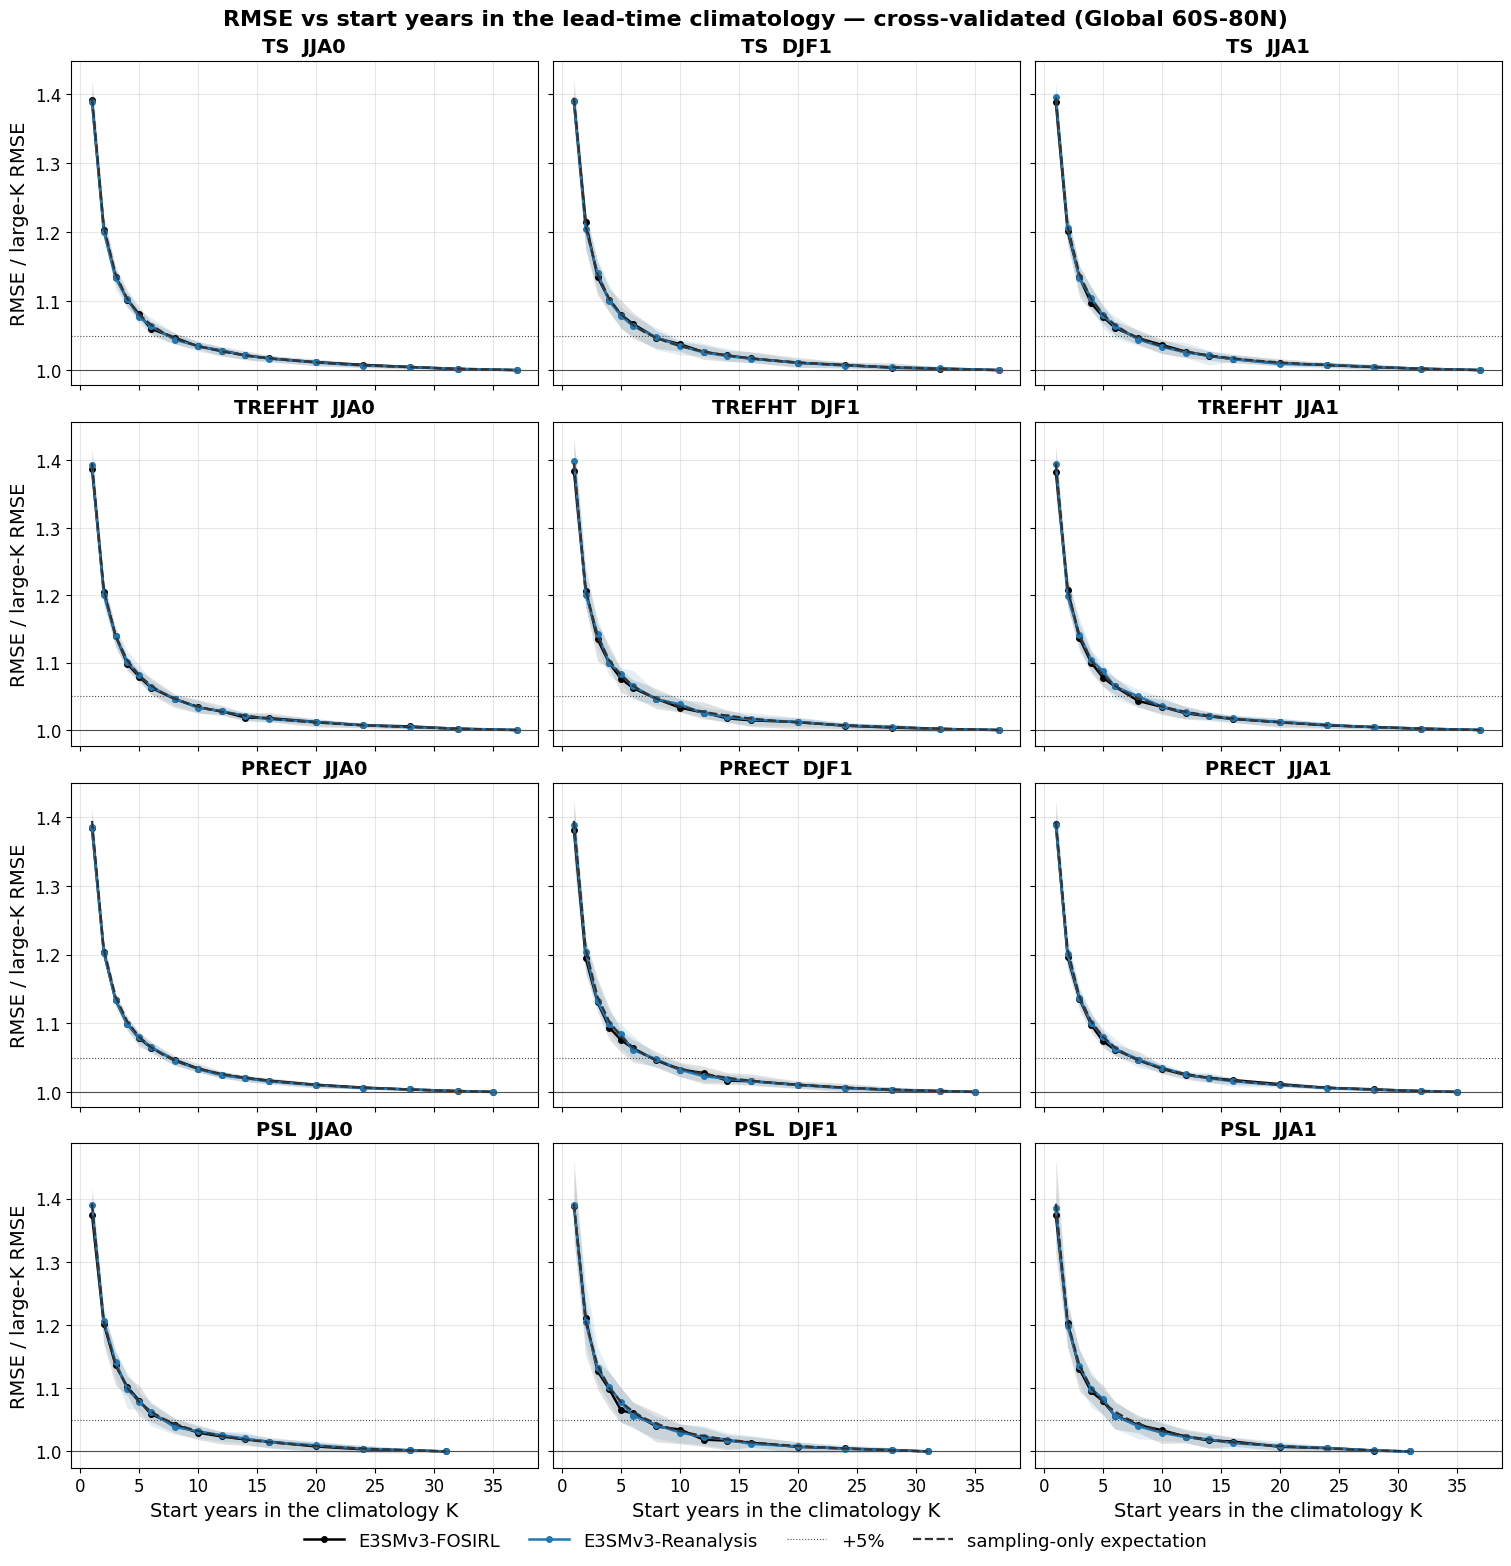

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_climatology_error_atm.png


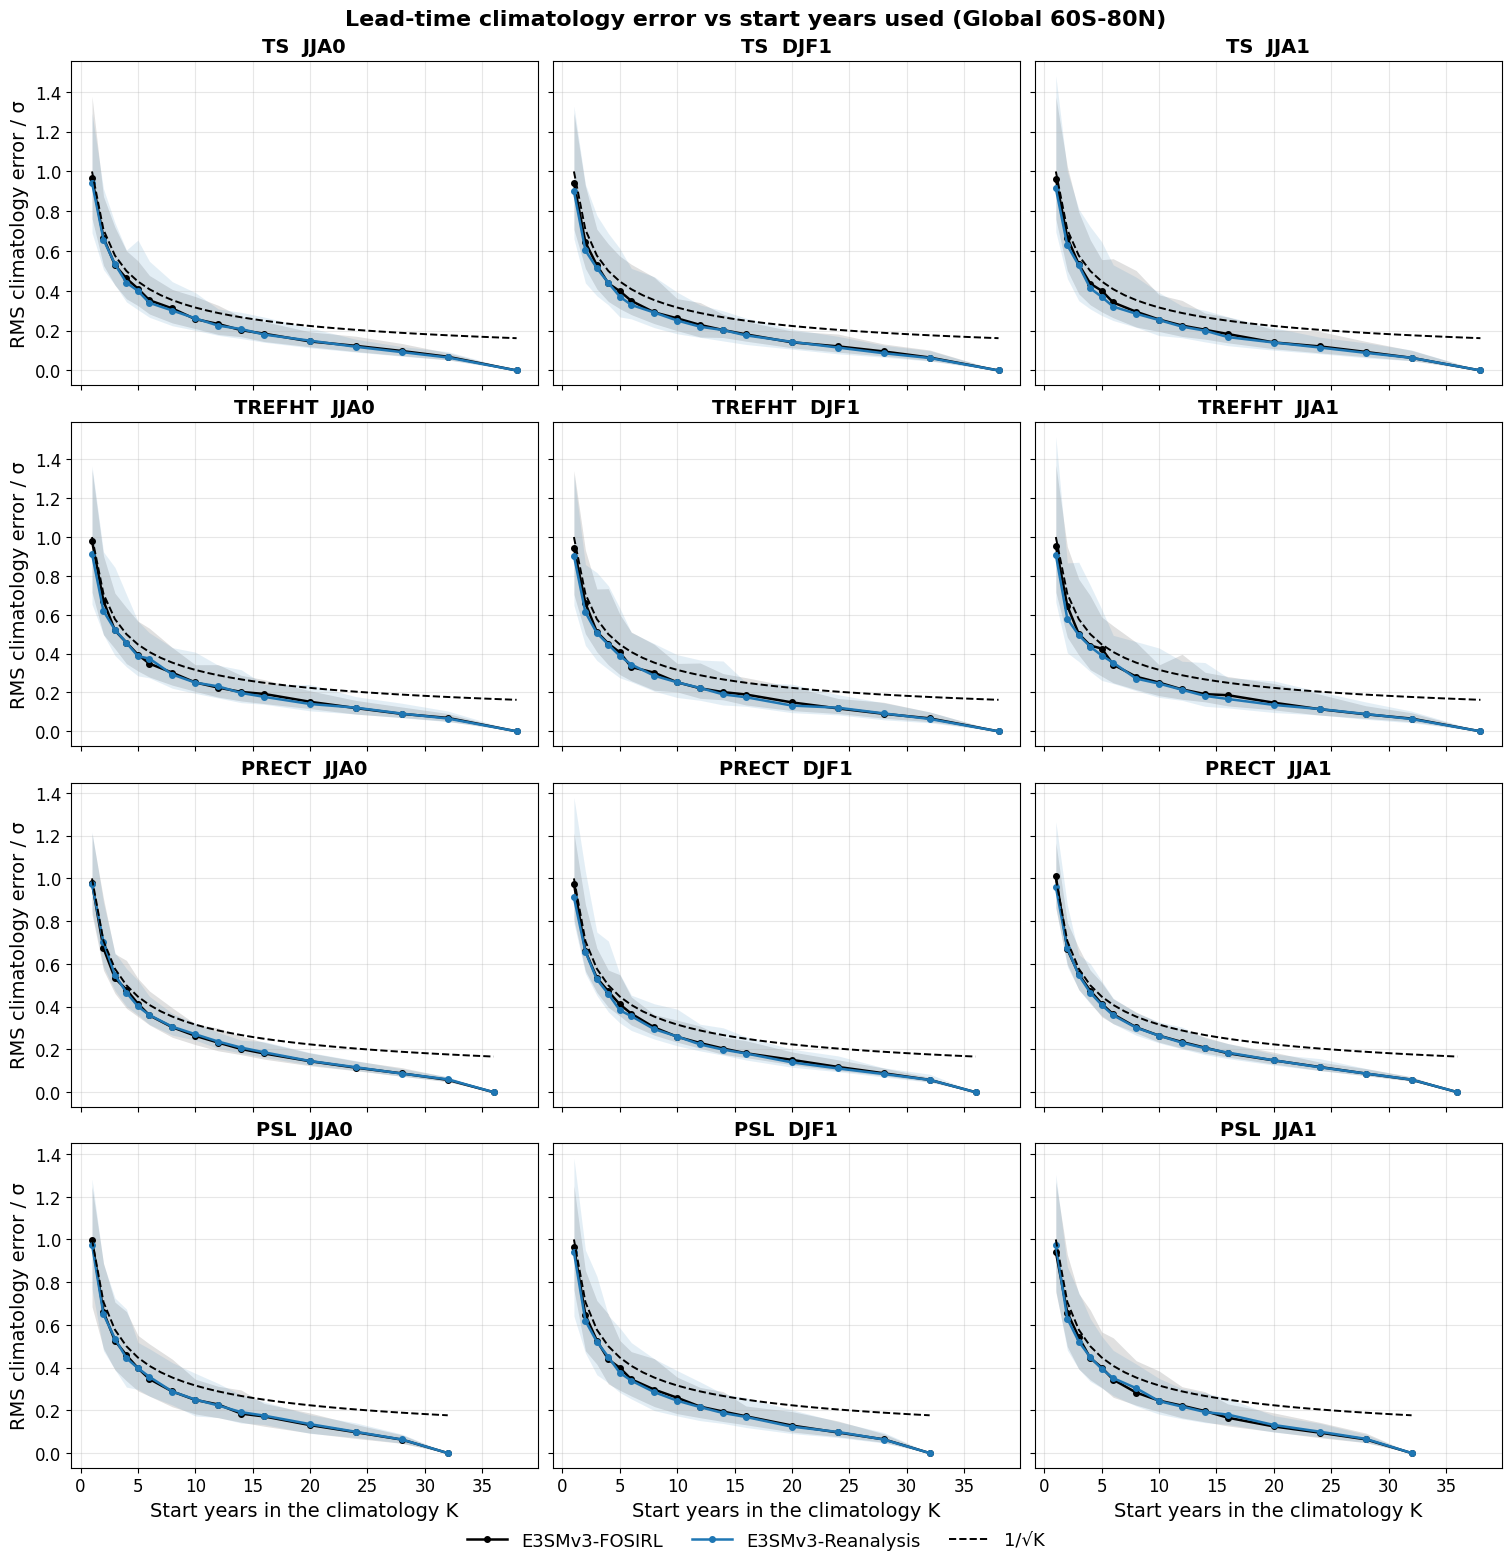

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_climatology_rmse_in-sample_sst.png


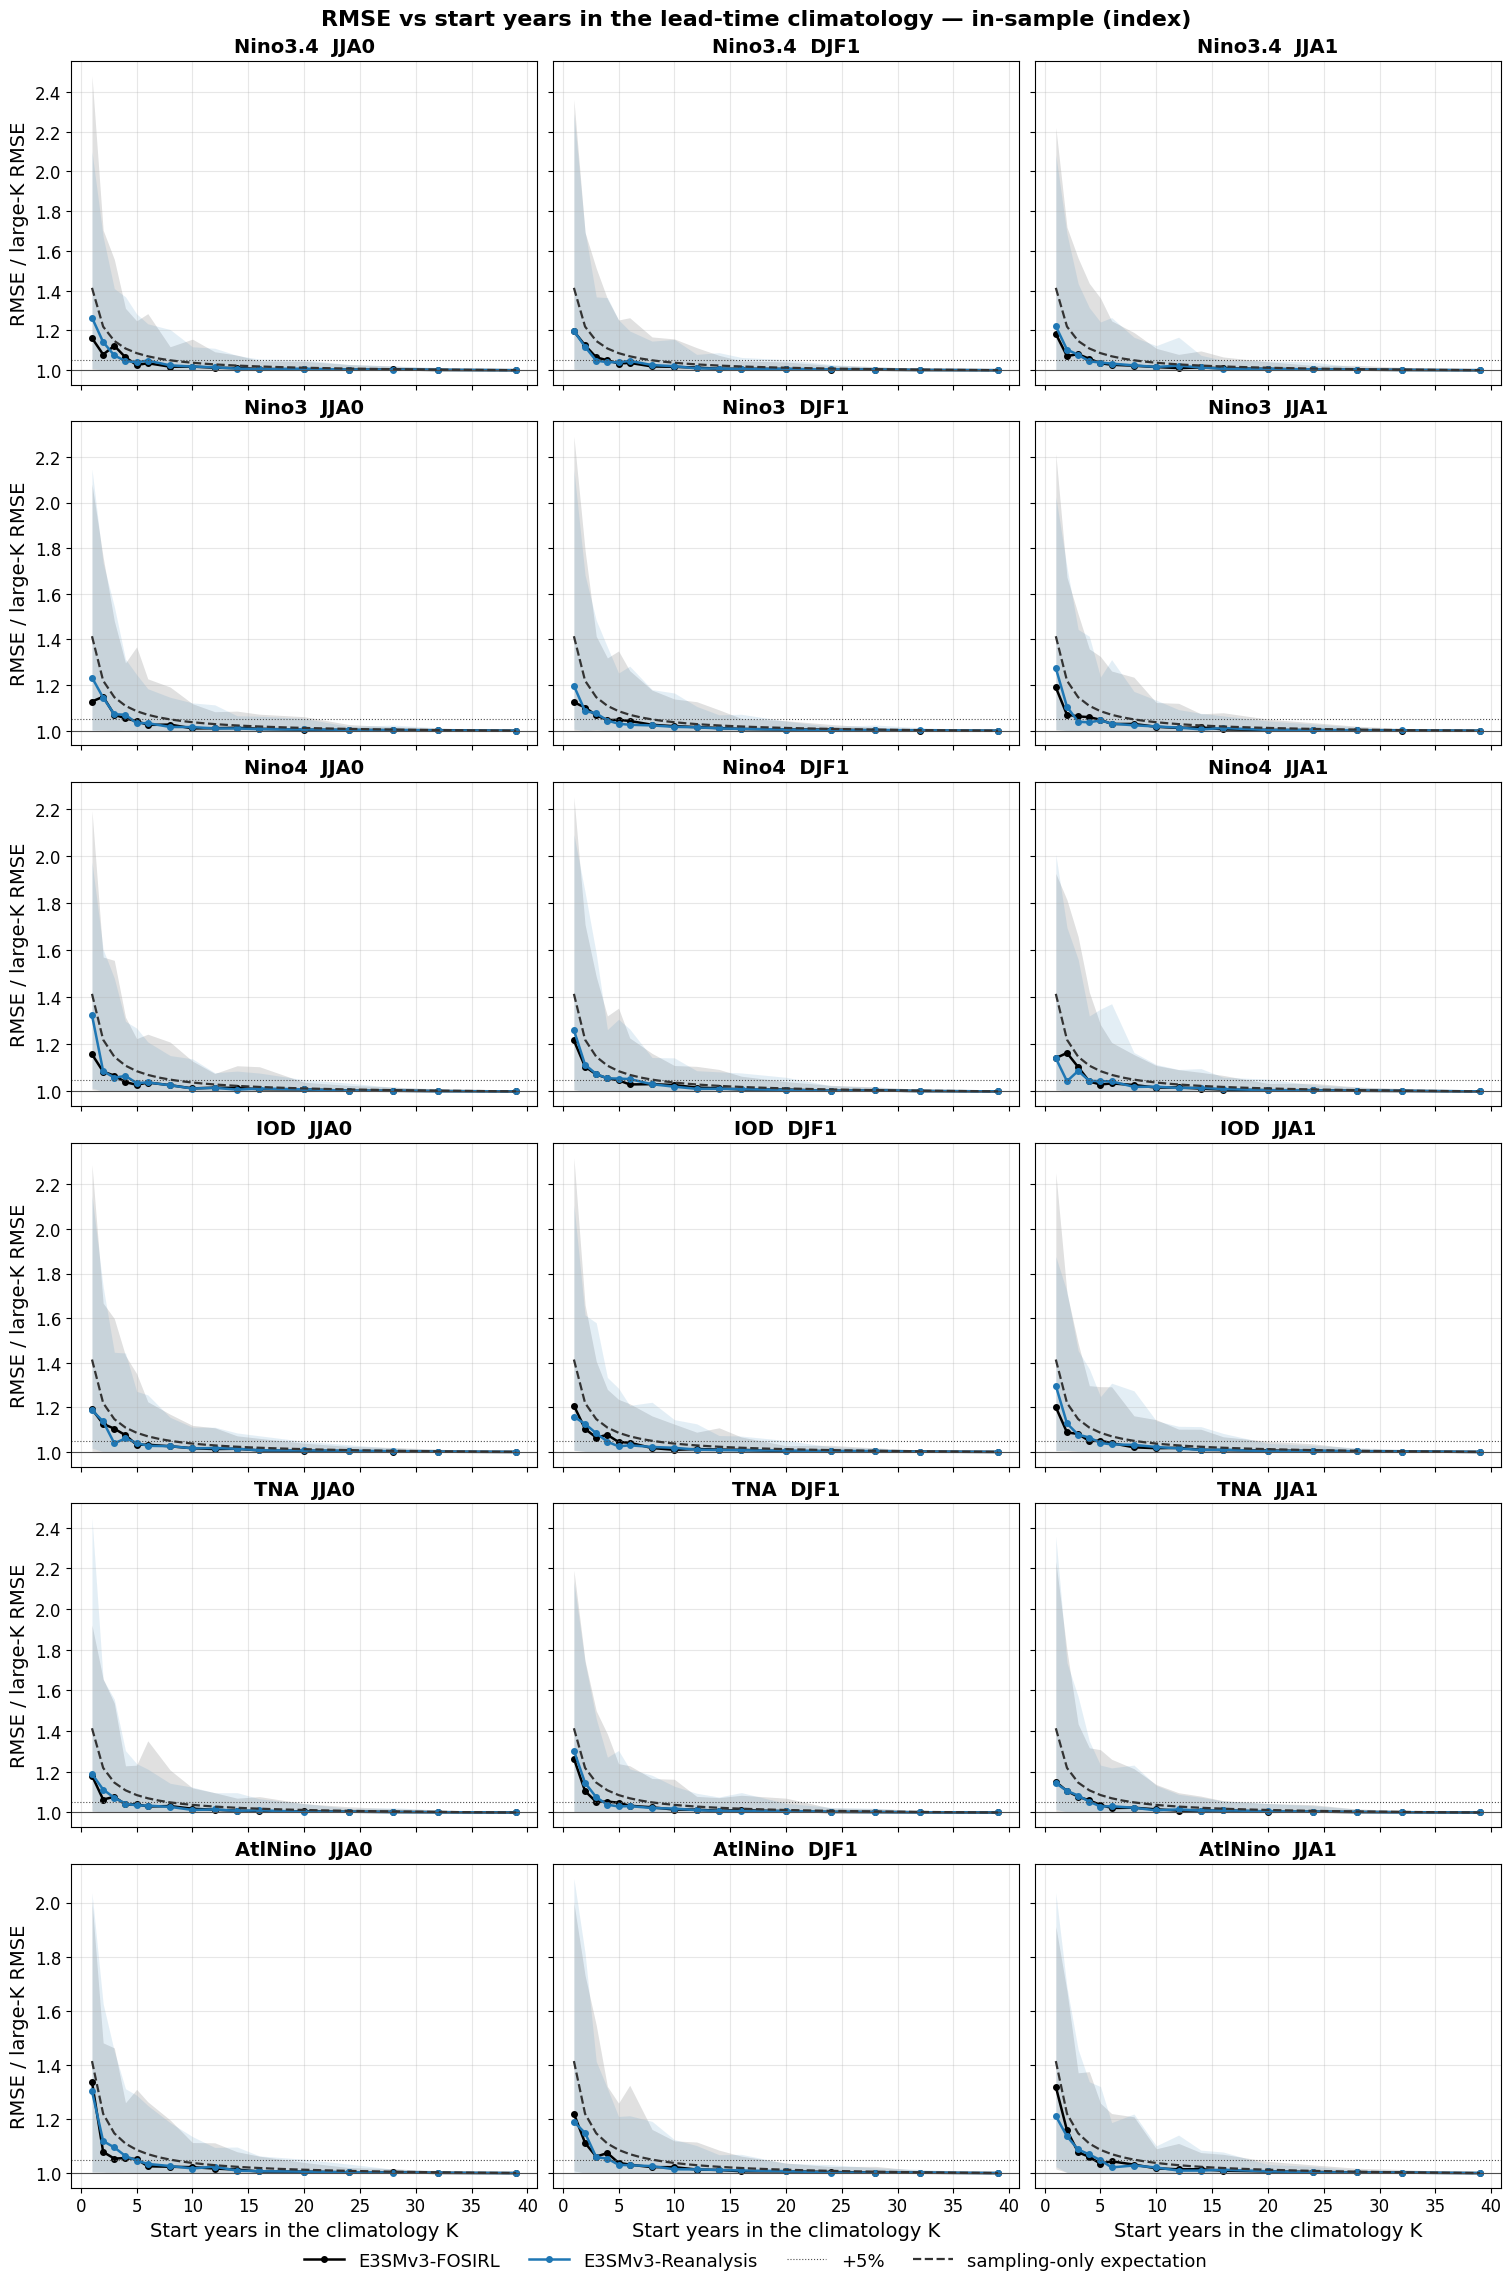

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_climatology_rmse_cross-validated_sst.png


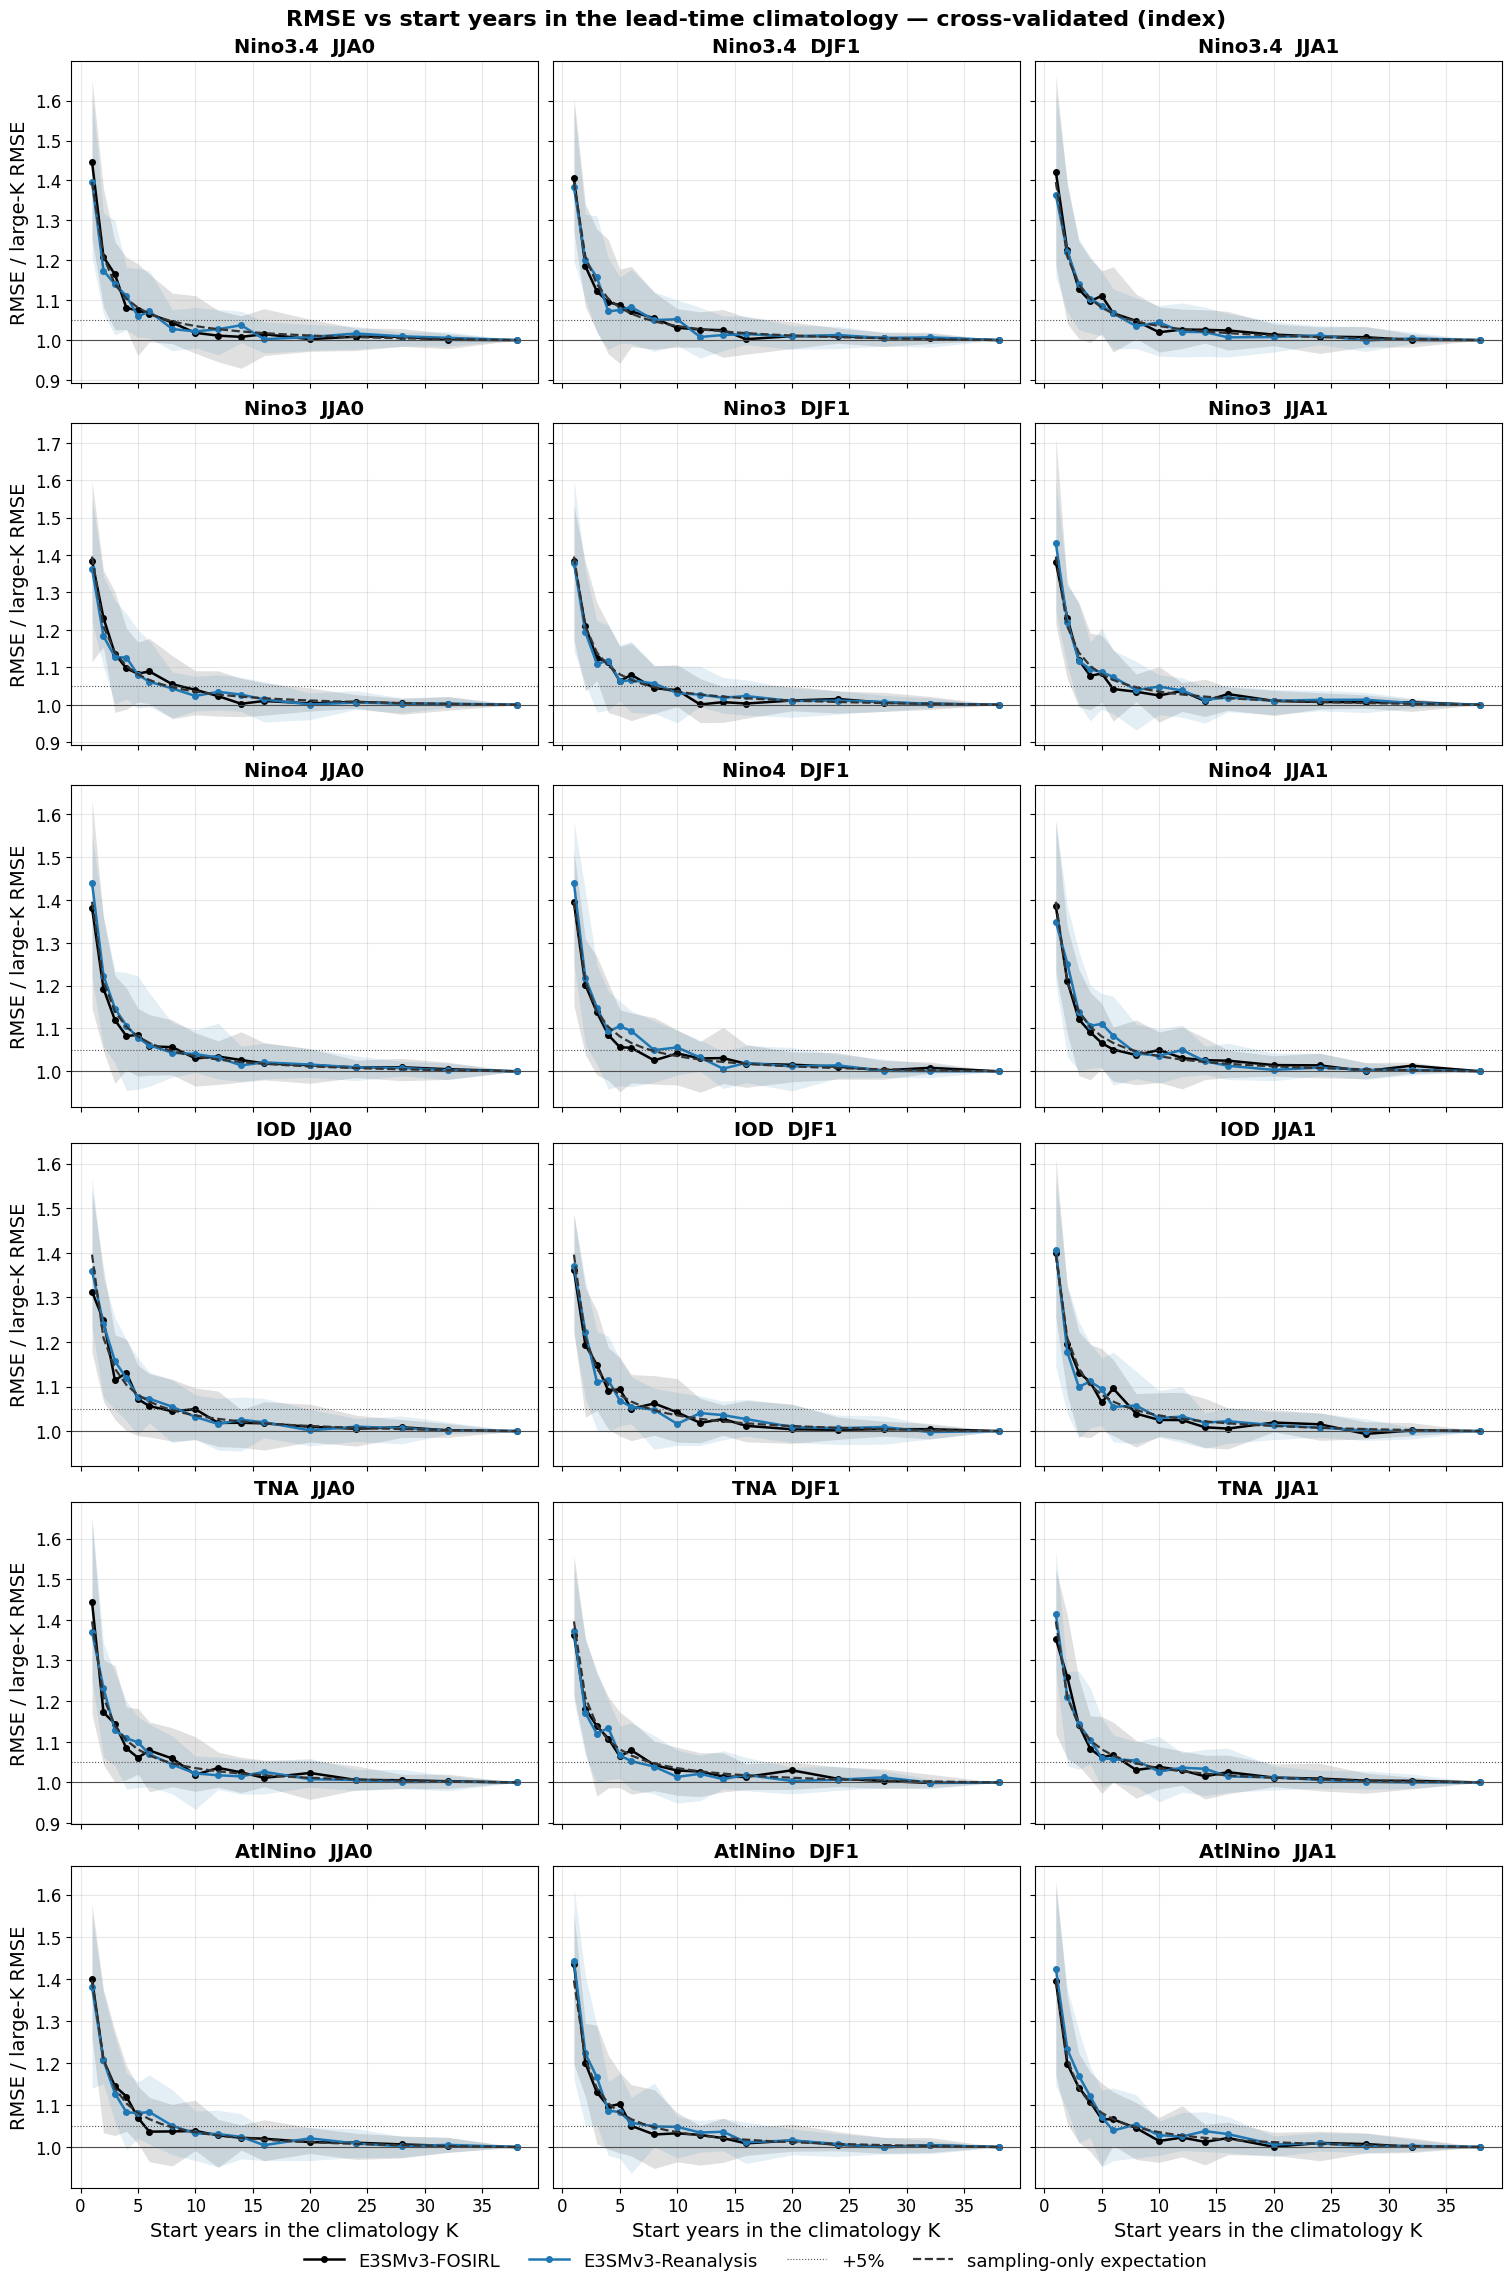

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_climatology_error_sst.png


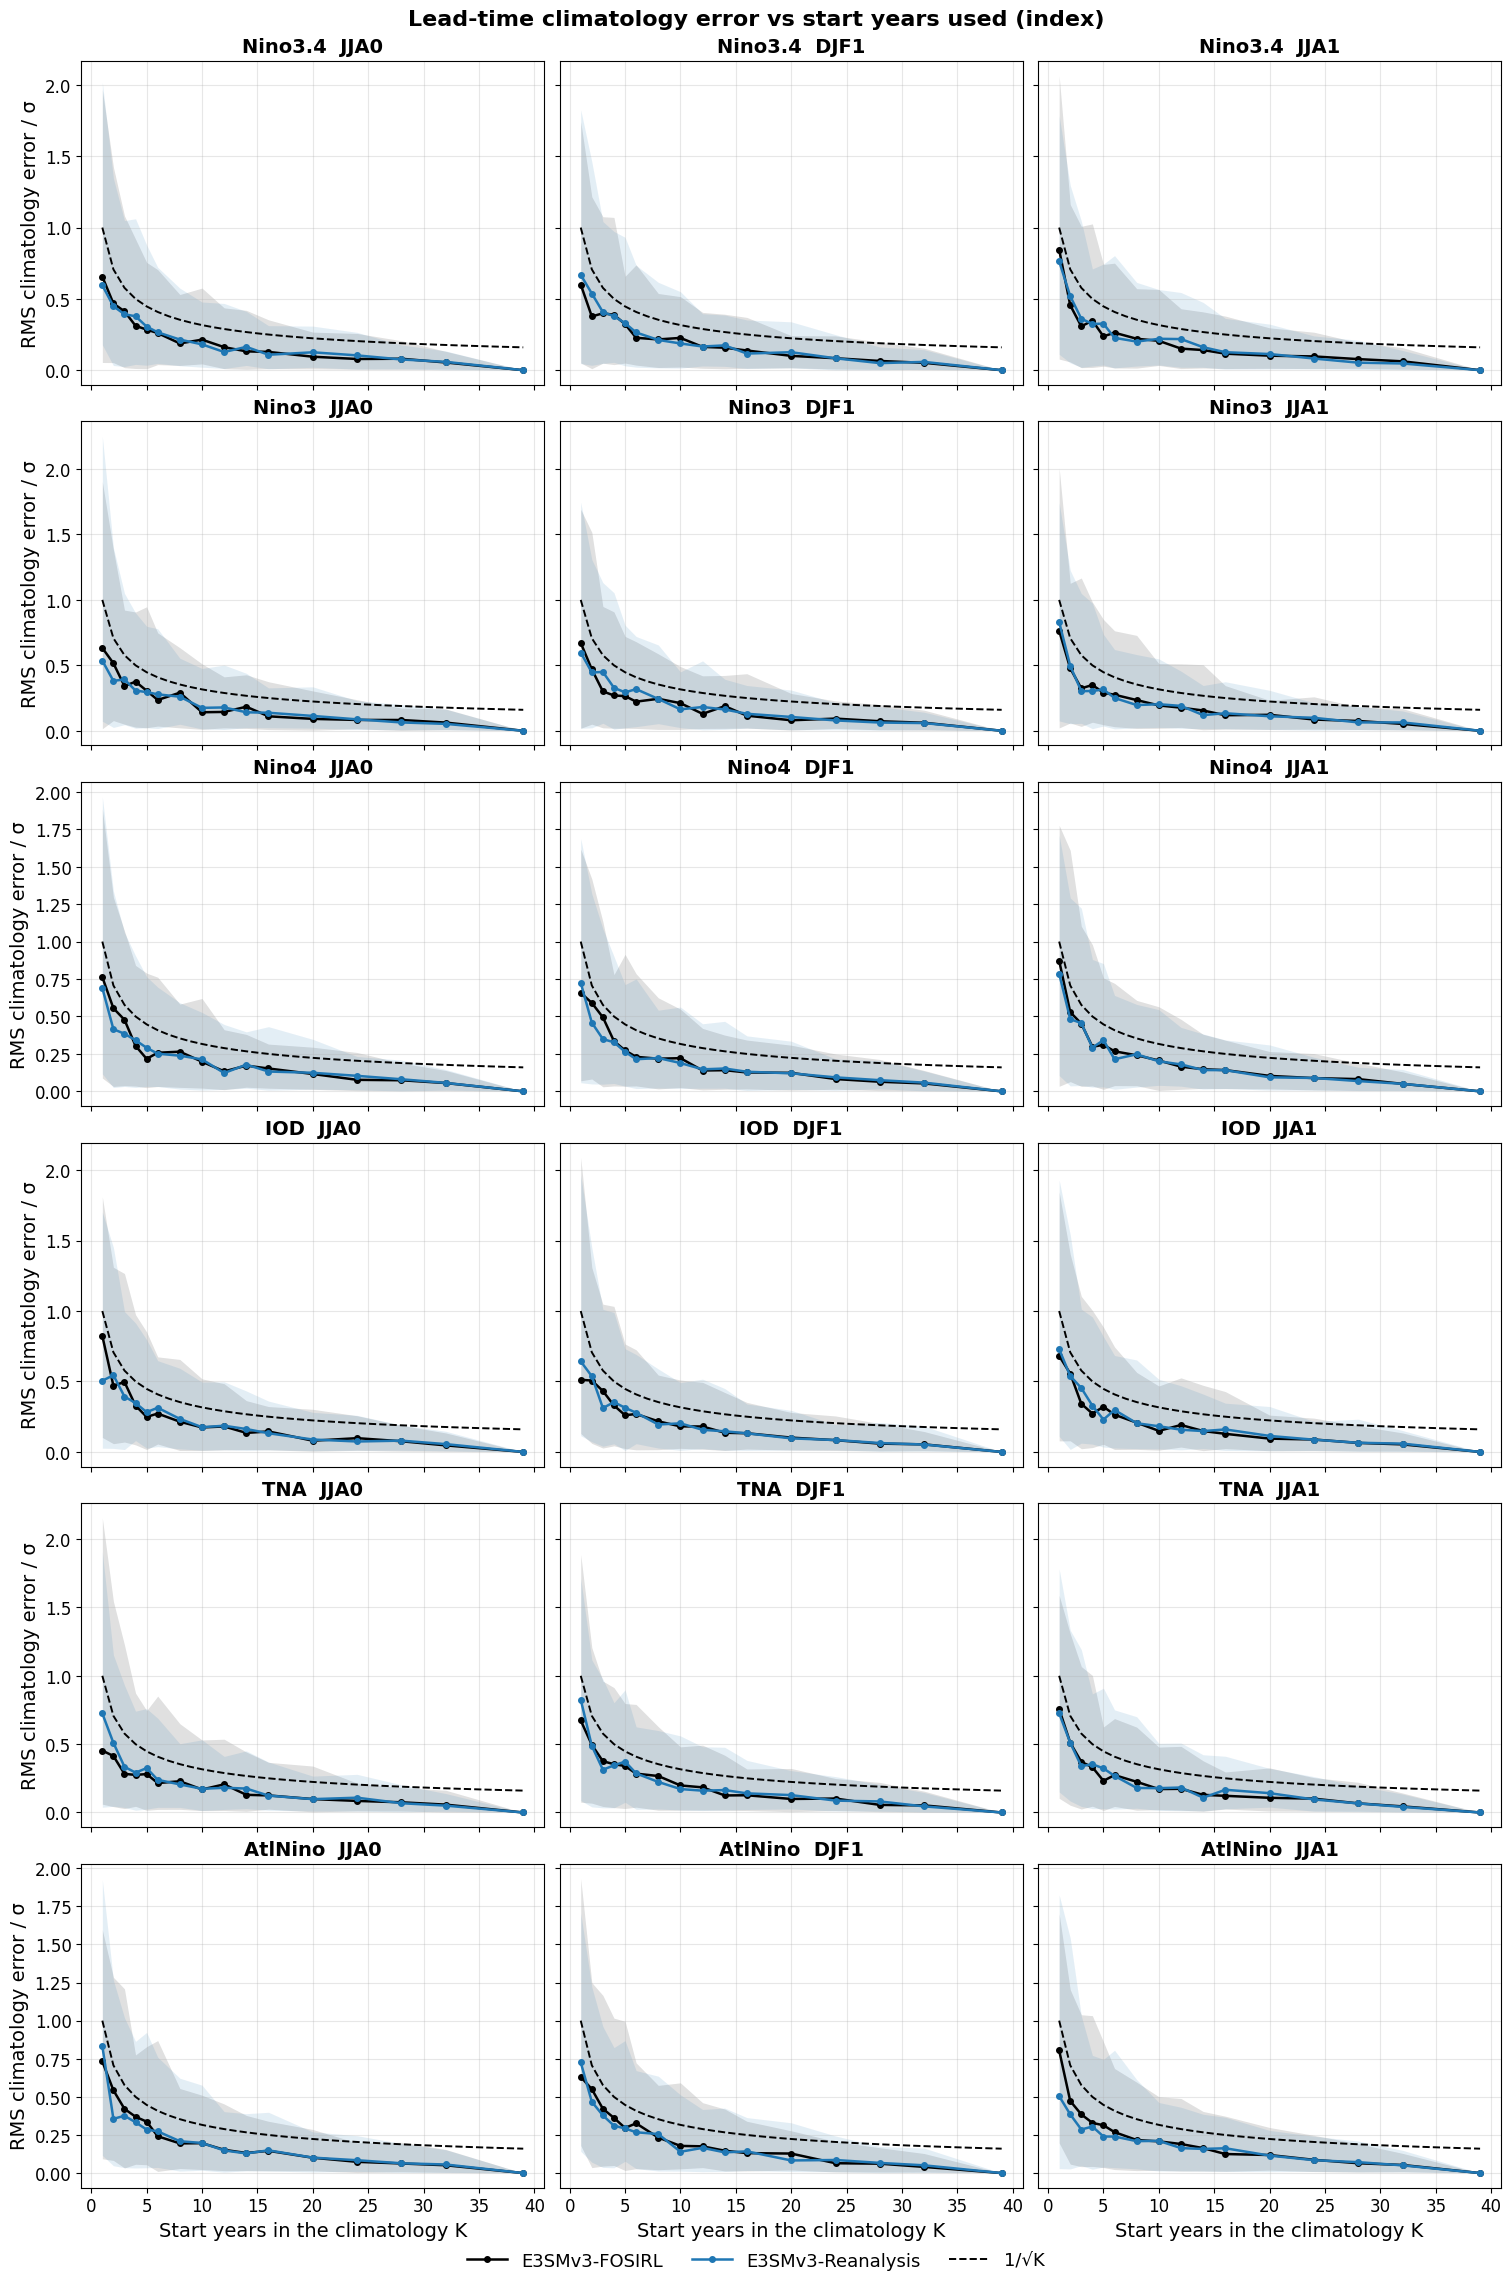

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_climatology_rmse_in-sample_lnd.png


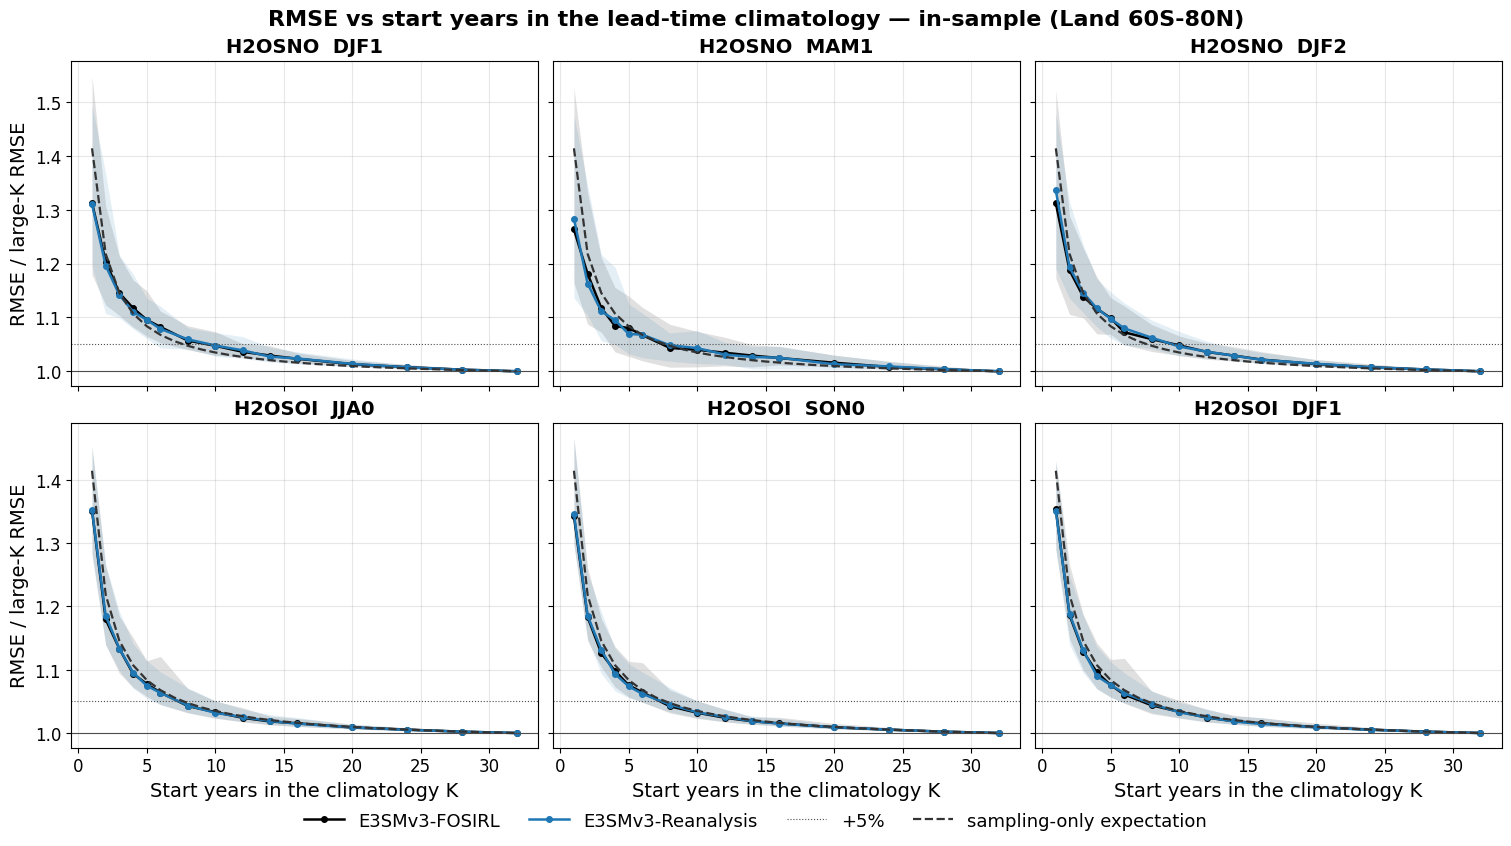

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_climatology_rmse_cross-validated_lnd.png


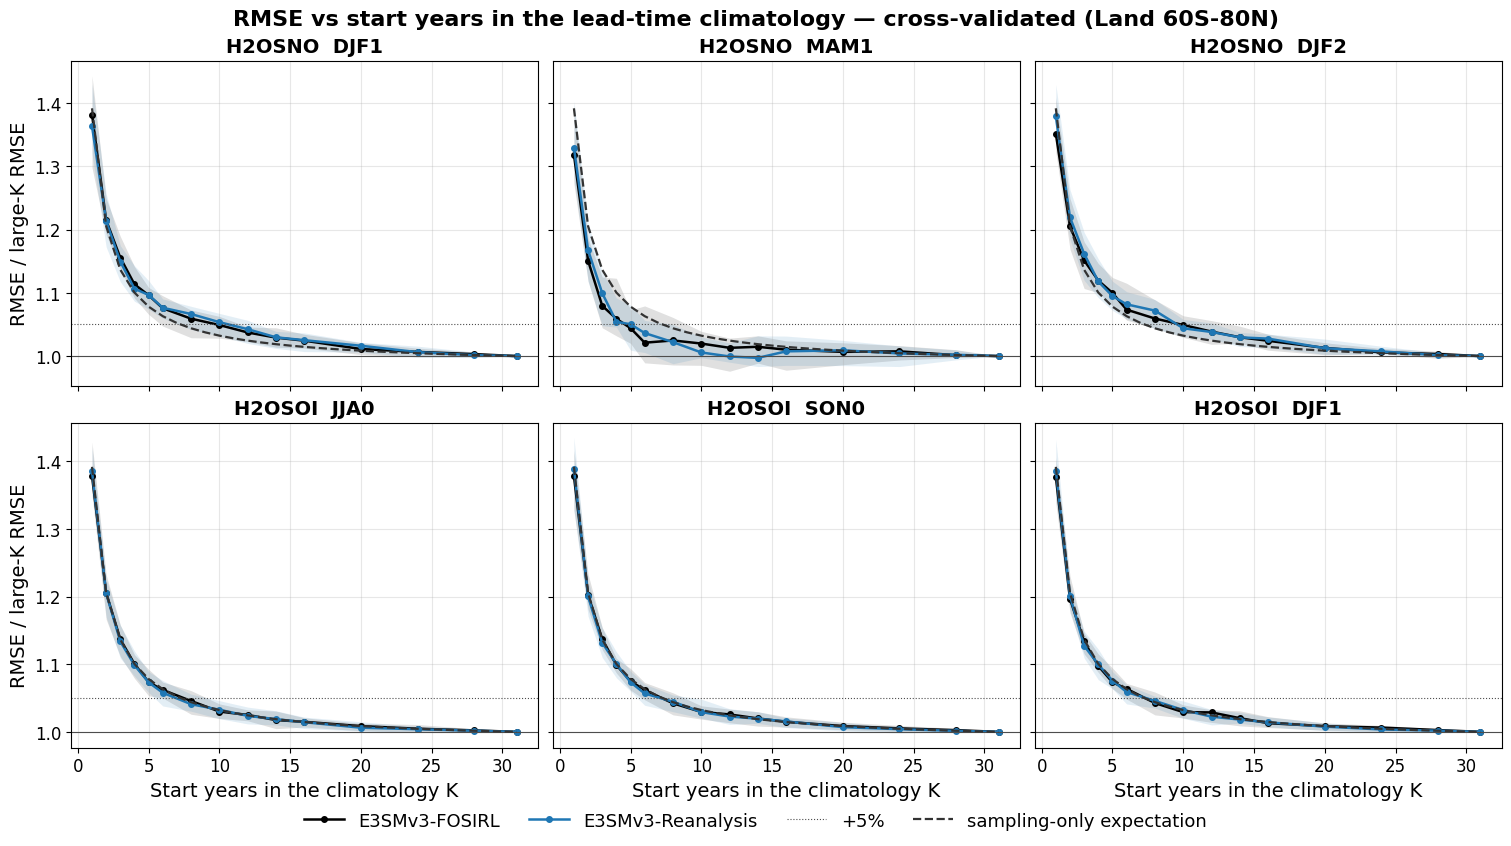

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_size/fig_sample_size_climatology_error_lnd.png


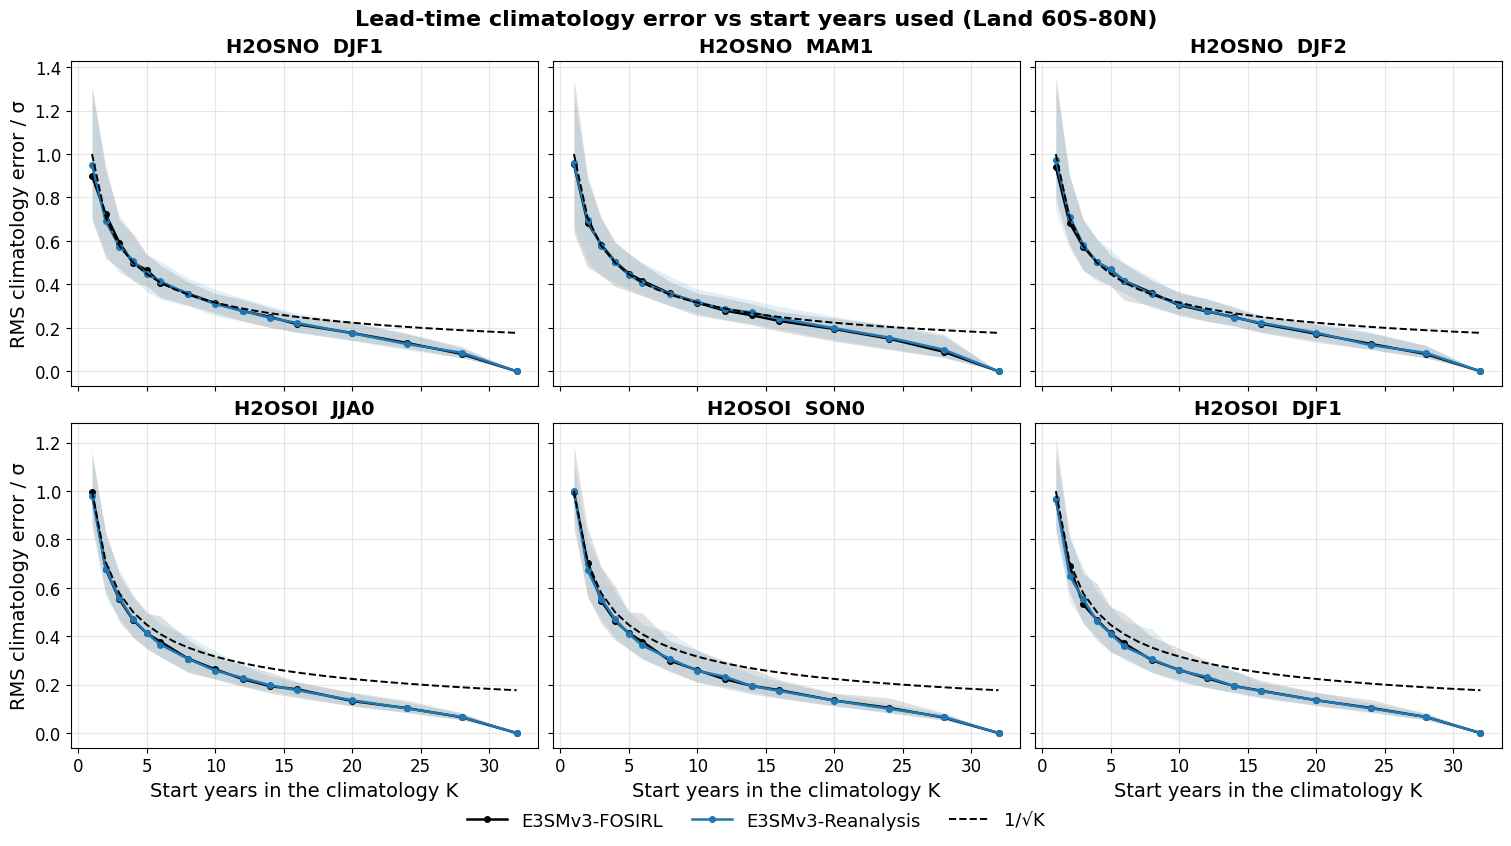

In [4]:
rows = []
for group, fields in DATA.items():
    for field, experiments in fields.items():
        for key, d in experiments.items():
            members = ss.year_members(d["members"], MEMBERS, RANDOM_SEED)
            n_max = members.sizes["Y"]
            # Cross-validated draws hold one climatology per scored year, so fewer draws suffice.
            for variant, k_max, draw_fn, draws in (
                    ("in-sample", n_max, sss.random_subsets, N_DRAWS),
                    ("cross-validated", n_max - 1, sss.cross_validated_subsets, max(N_DRAWS // 4, 10))):
                for k in sorted({k for k in K_GRID if k <= k_max} | {k_max}):
                    weights = draw_fn(n_max, k, draws, rng)
                    scores = sss.climatology_subset_scores(members, d["obs"], weights, reduce=REDUCE[group])
                    rows += ss.summarize(scores, ["rmse", "nrmse", "clim_error", "bias"], group=group, field=field,
                                         experiment=key, variant=variant, clim_years=k, record_years=n_max)
        print(f"done: {group} {field}")
climatology = pd.DataFrame(rows)

# Normalize RMSE by its large-K reference: in-sample K = N (the workflow), cross-validated K = N - 1.
keys = ["group", "field", "experiment", "region", "lead", "variant"]
largest = climatology.groupby(keys).clim_years.transform("max")
ref = (climatology[(climatology.metric == "rmse") & (climatology.clim_years == largest)]
       .set_index(keys)["median"].rename("rmse_large_k"))
climatology = climatology.join(ref, on=keys)
ratio = climatology[climatology.metric == "rmse"].copy()
for col in ("p05", "median", "p95"):
    ratio[col] = ratio[col] / ratio["rmse_large_k"]
ratio["metric"] = "rmse_ratio"
climatology = pd.concat([climatology, ratio], ignore_index=True)
climatology.to_csv(TABLE_DIR / f"sample_size_climatology_init{INIT_MONTH:02d}.csv", index=False)


def tolerance_lines(ax, group, field, lead, panel):
    ax.axhline(1.0, color="0.3", lw=0.8)
    ax.axhline(1 + CLIM_TOLERANCE, color="0.3", lw=0.8, ls=":", label=f"+{CLIM_TOLERANCE:.0%}")
    n = int(panel.record_years.max())
    k = np.arange(1, int(panel.clim_years.max()) + 1, dtype=float)
    if (panel.variant == "in-sample").all():
        expected = np.sqrt((1 + 1 / k - 2 / n) / (1 - 1 / n))
    else:
        expected = np.sqrt((1 + 1 / k) / (1 + 1 / (n - 1)))
    ax.plot(k, expected, color="0.2", ls="--", lw=1.6, zorder=5, label="sampling-only expectation")


def sampling_guide(ax, group, field, lead, panel):
    k = np.arange(1, int(panel.clim_years.max()) + 1)
    ax.plot(k, 1 / np.sqrt(k), "k--", lw=1.4, zorder=5, label="1/√K")


for group in DATA:
    for variant in ("in-sample", "cross-validated"):
        ss.plot_curves(climatology, DATA, group, "clim_years", "RMSE / large-K RMSE",
                       f"RMSE vs start years in the lead-time climatology — {variant} ({PLOT_REGION[group]})",
                       FIGURE_DIR / f"fig_sample_size_climatology_rmse_{variant}_{group}.png", metric="rmse_ratio",
                       variant=variant, extra=tolerance_lines, **PLOT)
    ss.plot_curves(climatology, DATA, group, "clim_years", "RMS climatology error / σ",
                   f"Lead-time climatology error vs start years used ({PLOT_REGION[group]})",
                   FIGURE_DIR / f"fig_sample_size_climatology_error_{group}.png", metric="clim_error",
                   variant="in-sample", extra=sampling_guide, **PLOT)

## Smallest stable climatology length

The smallest K from which the median RMSE stays within `CLIM_TOLERANCE` (and the 95th percentile within twice that) of its large-K value; worst lead shown.

In [5]:
rows = []
for (group, field, key, region, lead, variant), curve in climatology[climatology.metric == "rmse_ratio"].groupby(
        ["group", "field", "experiment", "region", "lead", "variant"]):
    curve = curve.sort_values("clim_years")
    k_min = sss.smallest_stable_size(curve.clim_years.tolist(), curve["median"], curve["p95"], 1.0, CLIM_TOLERANCE)
    rows.append(dict(group=group, field=field, experiment=key, region=region, lead=lead, variant=variant,
                     record_years=int(curve.record_years.iloc[0]), min_clim_years=k_min))
min_k = pd.DataFrame(rows)
min_k.to_csv(TABLE_DIR / f"sample_size_climatology_min_years_init{INIT_MONTH:02d}.csv", index=False)
(min_k[min_k.region.isin(PLOT_REGION.values())]
 .assign(min_clim_years=lambda t: t.min_clim_years.astype("float"))
 .pivot_table(index=["group", "field", "experiment"], columns="variant", values="min_clim_years", aggfunc="max"))

variant                        cross-validated  in-sample
group field   experiment                                 
atm   PRECT   E3SM-FOSIRL                  8.0        8.0
              E3SM-Reanalysis              8.0        8.0
      PSL     E3SM-FOSIRL                 10.0       10.0
              E3SM-Reanalysis              8.0       10.0
      TREFHT  E3SM-FOSIRL                  8.0        8.0
              E3SM-Reanalysis              8.0        8.0
      TS      E3SM-FOSIRL                  8.0        8.0
              E3SM-Reanalysis             10.0        8.0
lnd   H2OSNO  E3SM-FOSIRL                 10.0       10.0
              E3SM-Reanalysis             12.0       10.0
      H2OSOI  E3SM-FOSIRL                  8.0        8.0
              E3SM-Reanalysis              8.0        8.0
sst   AtlNino E3SM-FOSIRL                 12.0       14.0
              E3SM-Reanalysis             10.0       14.0
      IOD     E3SM-FOSIRL                 12.0       16.0
              E3SM-Reanalysis             12.0       16.0
      Nino3   E3SM-FOSIRL                 12.0       16.0
              E3SM-Reanalysis             14.0       14.0
      Nino3.4 E3SM-FOSIRL                 14.0       16.0
              E3SM-Reanalysis             12.0       14.0
      Nino4   E3SM-FOSIRL                 16.0       20.0
              E3SM-Reanalysis             14.0       12.0
      TNA     E3SM-FOSIRL                 12.0       16.0
              E3SM-Reanalysis             12.0       16.0